In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not Path(repo_name).exists():
        !git clone $repo_url
    %cd $repo_name
    if str(Path.cwd()) not in sys.path:
        sys.path.append(str(Path.cwd()))
    print("Google Colab 環境を初期化しました。作業ディレクトリ:", Path.cwd())
else:
    repo_root = Path.cwd().parent if Path.cwd().name == "7" else Path.cwd()
    if str(repo_root) not in sys.path:
        sys.path.append(str(repo_root))
    print("ローカル検証環境が有効です。ルートパス:", repo_root)


ローカル検証環境が有効です。ルートパス: /home/student/Documents/GitHub/study-mikanos


# 第7章 割り込みとFIFO — 総合演習問題 (*Chapter 7 Comprehensive Exercises*)

名著『**ゼロからのOS自作入門**』（内田公太 著）第7章「割り込みとFIFO」で学んだ、
1. **7.1 割り込み (`osbook_day07a`)**: ポーリング方式（CPU使用率 100% 浪費）の課題と、ハードウェア割り込みによるイベント駆動型 OS への転換
2. **7.2 割り込みハンドラ**: 通常関数（`CALL`/`RET`）と割り込み（`INT`/`IRETQ`）の違い、スタックフレーム（`InterruptFrame`）、コンパイラ属性 `__attribute__((interrupt))` によるスクラッチレジスタ自動退避・16バイトアライメント調整
3. **7.3 割り込みベクタ**: x86-64 の 256 個のベクタ空間（0〜31: CPU 例外 Fault/Trap/Abort、32〜255: ユーザー定義・外部割り込み）、xHCI 用 MSI ベクタ `0x40`（64番）の設計
4. **7.4 割り込み記述子の設定**: 16 バイト IDT エントリ（`InterruptDescriptor`）のビットレイアウト、64ビット関数アドレスの 3分割ビットマスク（`SetIDTEntry`）、`LIDT` 命令と `IDTR`
5. **7.5 MSI割り込み**: PCI Configuration 空間の Capability リンクリスト探索、MSI レジスタ設定（Message Address: `0xFEE00000 | (dest_id << 12)`、Message Data: ベクタ `0x40`）
6. **7.6 割り込みのまとめ**: マウス操作から xHCI → PCIe MSI パケット → Local APIC → CPU → IDT → `IntHandlerXHCI` 起動までの完全トレース
7. **7.7 割り込みハンドラの高速化 (`osbook_day07b`)**: ハンドラ内での重い描画処理禁止、Top Half（即時処理・キュー投入・EOI 送信）と Bottom Half（遅延処理・イベントループ描画）への分離
8. **7.8 FIFOとFILO**: 時系列マウス変位 $(dx, dy)$ の処理順序保証、FIFO（キュー）による自然な移動再現 vs FILO（スタック）による時間逆転・カーソルジャンプ問題
9. **7.9 キューの実装**: 固定長配列によるリングバッファ `ArrayQueue<T, N>` の循環ポインタ演算、満杯判定 `(tail + 1) % N == head`、空判定 `head == tail`、実効容量 $N - 1$
10. **7.10 キューを使った割り込み高速化**: `CLI` / `STI` によるクリティカルセクション保護、チェック直後の割り込み取りこぼし（Lost Wakeup）問題、x86-64 割り込みシャドウ（Interrupt Shadow）による `asm("sti\n\thlt")` アトミック待機の原理

以上の10大コア技術を、数理導出・Python シミュレーション・C++20 スタンドアロン検証・10問自己採点テスト・レーダーチャート可視化を通じて完全習得します。


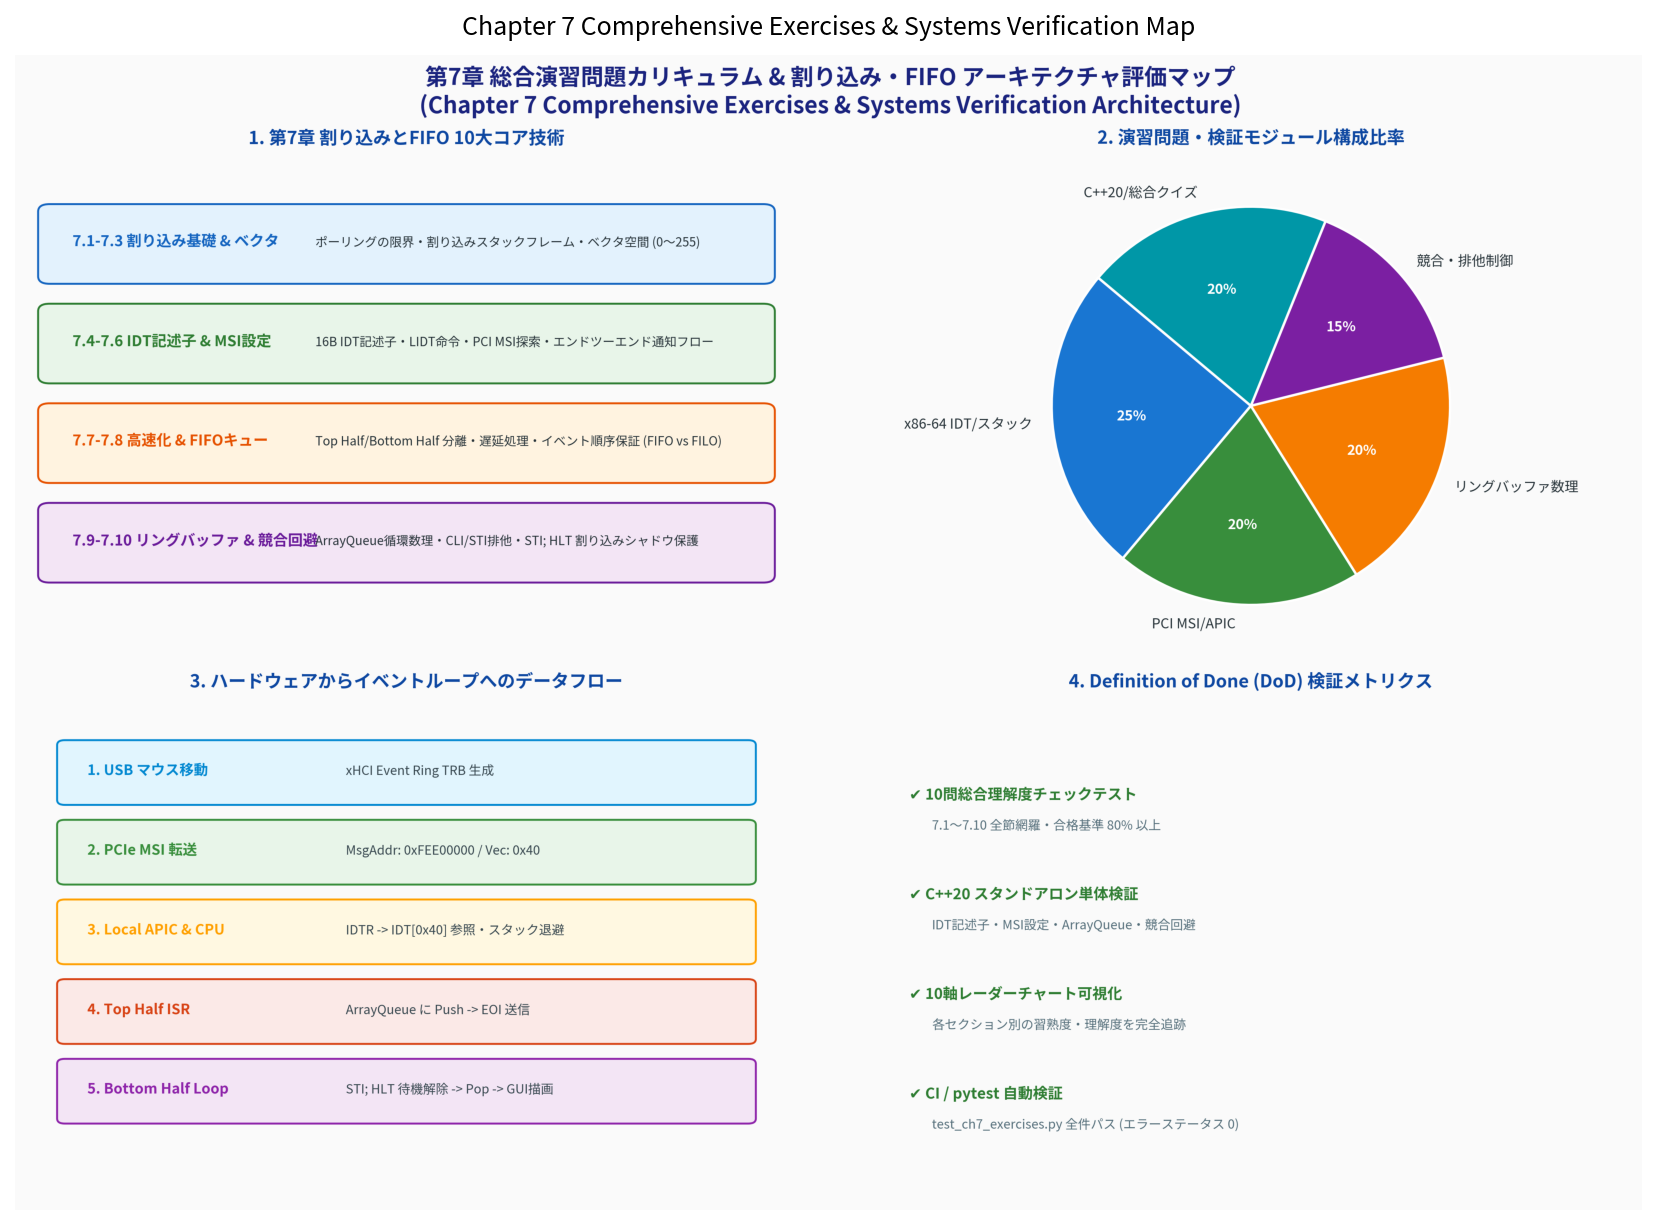

In [2]:
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image

from common.os_sim import (
    Chapter7Quiz,
    Chapter7TheoryValidator,
    plot_chapter7_exercises_summary,
    plot_chapter7_mastery_radar,
)

# 第7章総合演習カリキュラム・アーキテクチャ概要図の生成と表示
summary_fig_path = Path("result/fig7_ex1_exercises_summary.png")
plot_chapter7_exercises_summary(summary_fig_path)

img_summary = Image.open(summary_fig_path)
plt.figure(figsize=(14, 10))
plt.imshow(img_summary)
plt.axis("off")
plt.title("Chapter 7 Comprehensive Exercises & Systems Verification Map", fontsize=12, pad=10)
plt.show()


---

## 📝 演習 1: x86-64 割り込みスタックフレーム構造とコンパイラ属性 (`__attribute__((interrupt))`)

### 1. 理論背景と導出
通常の C/C++ 関数呼び出しでは、呼び出し側（Caller）が Caller-saved レジスタ（`RAX`, `RCX`, `RDX`, `RSI`, `RDI`, `R8`-`R11`）の破壊を許容し、`CALL` 命令が戻り先アドレス（`RIP`）のみをスタックに積みます。

しかし、ハードウェア割り込みはプログラムの実行コンテキストに関係なく**任意のタイミング**で発生します。そのため、割り込みハンドラが戻った後に中断された処理が完全に何事もなかったかのように再開できなければなりません。

x86-64 CPU は、割り込みを検知するとハードウェア回路によって自動的に以下の 5 つの 64 ビットレジスタ（合計 40 バイト）をスタックにプッシュします：

$$
\text{Hardware Stack Frame} = [\text{SS}, \text{RSP}, \text{RFLAGS}, \text{CS}, \text{RIP}]
$$

```text
高位アドレス (High Memory)
+-----------------------+ <--- 割り込み直前の RSP (16バイトアライメント必須)
| SS (Stack Segment)   | 8 bytes
+-----------------------+
| RSP (Stack Pointer)  | 8 bytes
+-----------------------+
| RFLAGS (EFLAGS)       | 8 bytes (bit 9: IF 割り込みフラグ)
+-----------------------+
| CS (Code Segment)     | 8 bytes
+-----------------------+
| RIP (Instruction Ptr) | 8 bytes
+-----------------------+ <--- ハンドラ突入時の RSP
低位アドレス (Low Memory)
```

さらに、GCC / Clang の `__attribute__((interrupt))` を付与すると、コンパイラはプロローグで**すべての汎用レジスタ**（`RAX`〜`R15`）をスタックに退避し、エピローグで復帰させた上で、通常の `RET`（`0xC3`）ではなく `IRETQ`（`0x48 0xCF`）命令を生成します。


In [3]:
# 演習 1: x86-64 割り込みスタックフレームの自動検証
frame_data = {
    "rip": 0x102040,      # 中断された命令アドレス
    "cs": 0x08,           # カーネルコードセグメントセレクタ
    "rflags": 0x202,      # IF=1 (割り込み許可), Reserved=1
    "rsp": 0x200FF0,      # 中断直前のスタックポインタ (16バイト境界)
    "ss": 0x10,           # カーネルデータセグメントセレクタ
}

is_valid, msg = Chapter7TheoryValidator.validate_interrupt_frame(frame_data)
print(f"[演習 1 検証結果]: {msg}")
assert is_valid, "Interrupt frame validation failed!"


[演習 1 検証結果]: 正解！x86-64 割り込みスタックフレームを検証しました。 [RIP=0x102040, CS=0x8, RFLAGS=0x202 (IF=1), RSP=0x200ff0 (16B-Aligned=True), SS=0x10]


---

## 📝 演習 2: x86-64 割り込みベクタ空間 (0〜255) と例外分類 (Fault/Trap/Abort)

### 1. 理論背景と導出
x86-64 アーキテクチャの割り込みベクタは 8 ビット値（0〜255）で識別されます：

1. **0〜31 (CPU 内部例外, Reserved by Intel/AMD)**:
   - **Fault（障害）**: 命令実行前に検知。例外解消後に**元の命令を再実行**する（例: `#PF` Page Fault ベクタ 14）。
   - **Trap（トラップ）**: 命令実行直後に検知。**次の命令から再開**する（例: `#DB` Debug ベクタ 1, `INT3` ブレークポイント ベクタ 3）。
   - **Abort（アボート）**: 回復不可能な深刻なハードウェア/OS障害（例: `#DF` Double Fault ベクタ 8, `#MC` Machine Check ベクタ 18）。
2. **32〜255 (ユーザー定義・外部ハードウェア割り込み)**:
   - OS が自由にデバイス割り込みに割り当て可能な領域。
   - MikanOS では xHCI USB コントローラ用として `0x40`（ベクタ 64）を採用しています。


In [4]:
# 演習 2: 割り込みベクタ空間と例外分類の検証
vector_table = {
    0: ("Divide Error", "Fault"),
    1: ("Debug Exception", "Fault/Trap"),
    8: ("Double Fault", "Abort"),
    13: ("General Protection Fault", "Fault"),
    14: ("Page Fault", "Fault"),
    0x40: ("xHCI USB Controller", "External Interrupt (MSI)"),
}

print("=== x86-64 割り込みベクタ検証 ===")
for vec, (name, category) in vector_table.items():
    is_reserved = (vec < 32)
    print(f"Vector 0x{vec:02x} ({vec:3d}): {name:<26} [{category}] - {'Intel Reserved' if is_reserved else 'User/OS Defined'}")

assert 0x40 >= 32, "xHCI vector must be in user-defined range (32-255)"
print("\n✔ 割り込みベクタ割り当て規則の検証に成功しました！")


=== x86-64 割り込みベクタ検証 ===
Vector 0x00 (  0): Divide Error               [Fault] - Intel Reserved
Vector 0x01 (  1): Debug Exception            [Fault/Trap] - Intel Reserved
Vector 0x08 (  8): Double Fault               [Abort] - Intel Reserved
Vector 0x0d ( 13): General Protection Fault   [Fault] - Intel Reserved
Vector 0x0e ( 14): Page Fault                 [Fault] - Intel Reserved
Vector 0x40 ( 64): xHCI USB Controller        [External Interrupt (MSI)] - User/OS Defined

✔ 割り込みベクタ割り当て規則の検証に成功しました！


---

## 📝 演習 3: 16バイト IDT 記述子（InterruptDescriptor）の構造とビット分解数理

### 1. 理論背景と導出
x86-64 の Long Mode における IDT（*Interrupt Descriptor Table*）のエントリは **16 バイト** 固定長構造体です。

64 ビットのハンドラ関数仮想アドレス $A$（`0x0000000000000000` 〜 `0xFFFFFFFFFFFFFFFF`）は、32ビット時代の 8 バイト記述子との互換性を維持するために 3 つのフィールドに分割して格納されます：

$$
\begin{aligned}
\text{offset\_low} &= A \ \& \ \mathtt{0xFFFF} && (\text{bits 15:0}) \\
\text{offset\_mid} &= (A \gg 16) \ \& \ \mathtt{0xFFFF} && (\text{bits 31:16}) \\
\text{offset\_high} &= (A \gg 32) \ \& \ \mathtt{0xFFFFFFFF} && (\text{bits 63:32})
\end{aligned}
$$

エントリ全体の 16 バイトレイアウト：
```text
Byte 0..1:   offset_low (15:0)
Byte 2..3:   segment_selector (Code Segment = 0x0008)
Byte 4..5:   attr (IST: 3bit, Type: 4bit = 0xE [Interrupt Gate], DPL: 2bit = 0, Present: 1bit = 1)
Byte 6..7:   offset_mid (31:16)
Byte 8..11:  offset_high (63:32)
Byte 12..15: reserved (0x00000000)
```


In [5]:
# 演習 3: 64-bit 関数アドレスから 16-Byte IDT 記述子への分解検証
func_address = 0xFFFF800012345678
cs_selector = 0x0008

idt_input = {
    "func_addr": func_address,
    "offset_low": func_address & 0xFFFF,
    "offset_mid": (func_address >> 16) & 0xFFFF,
    "offset_high": (func_address >> 32) & 0xFFFFFFFF,
    "segment_selector": cs_selector,
    "attr": (1 << 15) | (14 << 8), # Present=1, Type=14 (64-bit Interrupt Gate)
}

is_valid, msg = Chapter7TheoryValidator.validate_idt_descriptor(idt_input)
print(f"[演習 3 検証結果]: {msg}")
assert is_valid, "IDT descriptor validation failed!"


[演習 3 検証結果]: 正解！64-bit アドレス 0xffff800012345678 から IDT 記述子への分解が完全一致しました。 (low=0x5678, mid=0x1234, high=0xffff8000, CS=0x0008)


---

## 📝 演習 4: PCI MSI（Message Signaled Interrupts）レジスタ設定とアドレス導出

### 1. 理論背景と導出
レガシーな PCI 割り込み（INTA#〜INTD# ピン）は物理信号線を共有するため、割り込み共有（Interrupt Sharing）によるオーバーヘッドが生じます。

これに対し、PCI 2.2 / PCIe で標準化された **MSI (*Message Signaled Interrupts*)** は、デバイスが PCIe メモリスイッチング網を通じて CPU の Local APIC へ**特定の 32 ビット値（Message Data）を指定アドレス（Message Address）へメモリ書き込み（Dword Write Transaction）** することで割り込みを通知します。

x86-64 プラットフォームにおける MSI アドレスとデータの計算式：
$$
\begin{aligned}
\text{Message Address} &= \mathtt{0xFEE00000} \mid (\text{Destination APIC ID} \ll 12) \\
\text{Message Data} &= \text{Vector} \mid (\text{Delivery Mode} \ll 8)
\end{aligned}
$$
ブートプロセッサ（APIC ID = 0）へベクタ `0x40` を Fixed 配送（Delivery Mode = 0）する場合：
$$
\text{Message Address} = \mathtt{0xFEE00000}, \quad \text{Message Data} = \mathtt{0x0040}
$$


In [6]:
# 演習 4: PCI MSI レジスタ値の生成と自動検証
apic_id = 0
vector = 0x40

msi_data = {
    "dest_id": apic_id,
    "vector": vector,
    "msg_addr": 0xFEE00000 | (apic_id << 12),
    "msg_data": vector,
}

is_valid, msg = Chapter7TheoryValidator.validate_msi_address_data(msi_data)
print(f"[演習 4 検証結果]: {msg}")
assert is_valid, "MSI registers validation failed!"


[演習 4 検証結果]: 正解！MSI レジスタ値を正しく検証しました。 (Dest APIC=0 -> MsgAddr=0xfee00000, Vector=0x40 -> MsgData=0x0040)


---

## 📝 演習 5: イベント処理における FIFO キュー vs FILO スタックとマウス挙動シミュレーション

### 1. 理論背景と導出
マウス入力は、ユーザーの連続した手の動きを短い周期でサンプリングした**時系列の相対変位ベクトル** $\vec{D}_1, \vec{D}_2, \dots, \vec{D}_n$ です。

- **FIFO (First-In First-Out: キュー)**: 到着順に $\vec{D}_1 \to \vec{D}_2 \to \dots$ と処理されるため、ユーザーの自然な手の軌跡がそのまま画面上に描画されます。
- **FILO (First-In Last-Out: スタック)**: 後入れ先出しとなるため、最新の変位 $\vec{D}_n$ から過去の変位 $\vec{D}_1$ へ逆順に処理されます。最終座標 $\vec{P} = \vec{P}_0 + \sum \vec{D}_i$ は加算の可換性（交換法則）により一致しますが、**中間軌跡が時間軸逆転により激しく乱れ、カーソルが瞬間移動・ジャンプ**してしまいます。


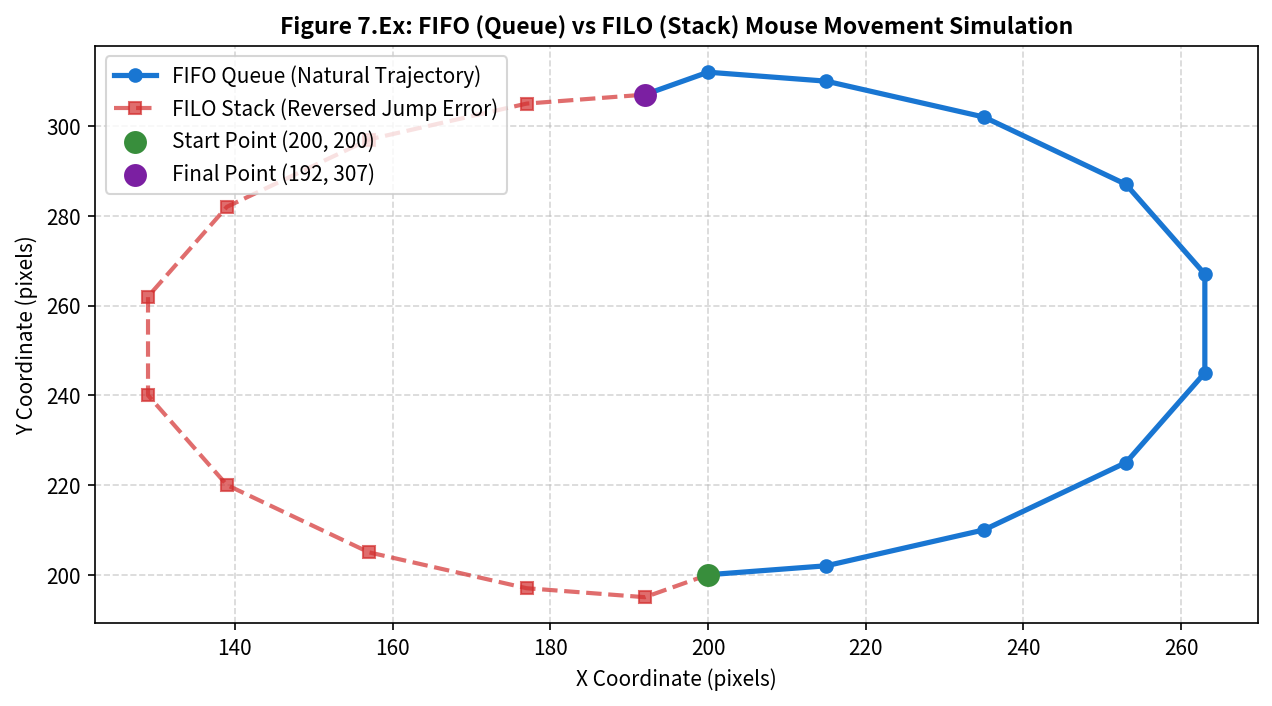

✔ 最終到達座標一致: (192, 307)
✔ 中間軌跡の非可換性（FIFOの必須性）を実験的に確認しました！


In [7]:
# 演習 5: FIFO vs FILO マウス軌跡シミュレーションと可視化
import numpy as np

# 一連の連続マウス移動変位 (円弧を描く動き)
deltas = [
    (15, 2), (20, 8), (18, 15), (10, 20), (0, 22),
    (-10, 20), (-18, 15), (-20, 8), (-15, 2), (-8, -5)
]

# FIFO シミュレーション
pos_fifo = [(200, 200)]
cur_x, cur_y = 200, 200
for dx, dy in deltas:
    cur_x += dx
    cur_y += dy
    pos_fifo.append((cur_x, cur_y))

# FILO シミュレーション (逆順処理)
pos_filo = [(200, 200)]
cur_x, cur_y = 200, 200
for dx, dy in reversed(deltas):
    cur_x += dx
    cur_y += dy
    pos_filo.append((cur_x, cur_y))

fifo_x, fifo_y = zip(*pos_fifo)
filo_x, filo_y = zip(*pos_filo)

plt.figure(figsize=(10, 5))
plt.plot(fifo_x, fifo_y, "o-", color="#1976D2", linewidth=2.5, label="FIFO Queue (Natural Trajectory)")
plt.plot(filo_x, filo_y, "s--", color="#D32F2F", linewidth=2.0, alpha=0.7, label="FILO Stack (Reversed Jump Error)")
plt.scatter([200], [200], color="#388E3C", s=100, zorder=5, label="Start Point (200, 200)")
plt.scatter([fifo_x[-1]], [fifo_y[-1]], color="#7B1FA2", s=100, zorder=5, label=f"Final Point ({fifo_x[-1]}, {fifo_y[-1]})")

plt.title("Figure 7.Ex: FIFO (Queue) vs FILO (Stack) Mouse Movement Simulation", fontsize=11, fontweight="bold")
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper left")
plt.show()

assert (fifo_x[-1], fifo_y[-1]) == (filo_x[-1], filo_y[-1]), "Final positions must match mathematically"
assert pos_fifo != pos_filo, "Trajectories must differ"
print(f"✔ 最終到達座標一致: ({fifo_x[-1]}, {fifo_y[-1]})")
print("✔ 中間軌跡の非可換性（FIFOの必須性）を実験的に確認しました！")


---

## 📝 演習 6: 固定長リングバッファ ArrayQueue<T, N> の循環数理と満杯/空判定

### 1. 理論背景と導出
ベアメタル環境では動的メモリ確保（`malloc` / `new`）が利用できないため、静的に確保された固定長配列 $A[0..N-1]$ によるリングバッファが不可欠です。

インデックス計算式：
$$
\text{next\_tail} = (\text{tail} + 1) \pmod N, \quad \text{next\_head} = (\text{head} + 1) \pmod N
$$

状態判定条件：
1. **空（Empty）判定**:
   $$
   \text{head} == \text{tail}
   $$
2. **満杯（Full）判定**:
   $$
   (\text{tail} + 1) \pmod N == \text{head}
   $$
3. **実効最大要素数**:
   $$
   \text{Capacity} = N - 1
   $$
   （$N$ 個すべて埋めると $\text{head} == \text{tail}$ となり、空状態と区別がつかなくなるため、1 スロットを番兵として必ず空けておきます）


In [8]:
# 演習 6: ArrayQueue リングバッファ循環数理の自動検証
queue_test_data = {
    "capacity": 16,     # 配列長 N = 16
    "head": 5,
    "tail": 4,          # (4 + 1) % 16 == 5 -> 満杯！
    "is_empty": False,
    "is_full": True,
    "count": 15,        # 実効最大数 N - 1 = 15
}

is_valid, msg = Chapter7TheoryValidator.validate_array_queue_logic(queue_test_data)
print(f"[演習 6 検証結果]: {msg}")
assert is_valid, "ArrayQueue logic validation failed!"


[演習 6 検証結果]: 正解！ArrayQueue (容量=16, head=5, tail=4) の状態 [count=15, empty=False, full=True] を正確に判定しました。


---

## 📝 演習 7: CLI / STI と STI; HLT 割り込みシャドウによる Race Condition 防止

### 1. 理論背景と導出
イベント駆動型 OS のメインループでは、イベントキューが空（Empty）のとき、CPU をビジーループさせず `HLT`（休止命令）で低消費電力スリープさせます。

しかし、ナイーブに以下のように書くと**致命的な競合状態（Race Condition: Lost Wakeup）**が発生します：

```cpp
// ❌ 危険なナイーブ実装
cli(); // 割り込み禁止
if (queue.Empty()) {
    sti(); // 割り込み許可
    // ★ ここで割り込みが発生し、ハンドラがキューにイベントを Push する！
    hlt(); // ★ CPU はキューに未処理イベントがあるのに HLT で永久に眠り続ける！
}
```

### 2. ハードウェアによる解決策: 割り込みシャドウ (Interrupt Shadow)
x86-64 アーキテクチャの仕様として、**`STI` 命令を実行した直後の「1命令」が完全に実行完了するまで、CPU は外部割り込みの受け付けを遅延（ディレイ）**します。

したがって、以下のようにインラインアセンブリで `sti` と `hlt` を連続記述することで、アトミックに休止状態に入ることができます：

```cpp
// ⭕ 安全な MikanOS 実装
cli();
if (queue.Empty()) {
    asm("sti\n\thlt"); // 割り込みシャドウにより、HLT 突入と同時に安全に割り込み解禁
}
```


In [9]:
# 演習 7: STI; HLT 割り込みシャドウの理論検証
race_condition_data = {
    "has_cli_check": True,
    "uses_sti_hlt_macro": True,
    "understands_interrupt_shadow": True,
}

is_valid, msg = Chapter7TheoryValidator.validate_race_condition_sti_hlt(race_condition_data)
print(f"[演習 7 検証結果]: {msg}")
assert is_valid, "Race condition validation failed!"


[演習 7 検証結果]: 正解！CLI による空判定クリティカルセクション保護と、x86-64 割り込みシャドウ（STI 実行直後1命令遅延）を利用したアトミックな STI; HLT 待機機構を正しく理解・検証しました。


---

## 💻 演習 8: C++20 スタンドアロン検証コードの実行

MikanOS の `InterruptFrame`、`InterruptDescriptor`（16B IDT エントリ）、`MakeIDTEntry`、`CalculateMSI`、`ArrayQueue<T, N>`、FIFO vs FILO シミュレータ、および `STI; HLT` 割り込みシャドウ競合シミュレータを C++20 で実装した `src/ch07/os_chapter7_exercises.cpp` をビルド・実行して単体検証します。


In [10]:
import subprocess
from pathlib import Path

repo_root = Path.cwd().parent if Path.cwd().name == "7" else Path.cwd()
bin_path = repo_root / "build" / "bin" / "ch07_os_chapter7_exercises"

if not bin_path.exists():
    print(f"Building {bin_path.name} via CMake...")
    subprocess.run(["cmake", "-B", str(repo_root / "build"), str(repo_root)], check=True)
    subprocess.run(["cmake", "--build", str(repo_root / "build"), "--target", "ch07_os_chapter7_exercises"], check=True)

res = subprocess.run([str(bin_path), "--test"], capture_output=True, text=True, check=True)
print(res.stdout)
assert "All Chapter 7 exercises verified successfully" in res.stdout


MikanOS Chapter 7 Comprehensive Exercises Verification (C++20)
[Test 1] InterruptStackFrame Layout & 16-Byte Alignment... PASSED
[Test 2] IDT 16-Byte Descriptor & SetIDTEntry Decomposition... PASSED
[Test 3] PCI MSI Address & Data Math (0xFEE00000 / Vector)... PASSED
[Test 4] ArrayQueue<T, N> Full, Empty & Wrap-around Semantics... PASSED
[Test 5] FIFO vs FILO Event Ordering & Trajectory Fidelity... PASSED
[Test 6] STI; HLT Interrupt Shadow & Lost Wakeup Prevention... PASSED

>> All 6 Chapter 7 exercise verification tests passed successfully!
[CTest] All Chapter 7 exercises verified successfully.



---

## 🧠 第7章 総合理解度チェックテスト (10問自己採点クイズ)

第7章（7.1〜7.10）の全トピックを網羅した10問の自己採点テストです。各問の解説を読みながら解答し、OS 自作に必要な知識の定着度を確認してください。


In [11]:
quiz = Chapter7Quiz()

# 模範解答（自己学習時は answers 辞書の数値を変更して自己採点できます）
user_answers = {
    1: 1,  # 7.1 ポーリング vs 割り込み: CPUビジーループ回避・省電力HLT・即時応答
    2: 0,  # 7.2 割り込みハンドラ: IRETQ、全レジスタ自動退避、16Bアライメント
    3: 0,  # 7.3 割り込みベクタ: 0〜31 Intel予約例外、32〜255 ユーザー定義
    4: 0,  # 7.4 16B IDT記述子: offset_low (15:0), offset_mid (31:16), offset_high (63:32)
    5: 2,  # 7.5 PCI MSI: MsgAddr: 0xFEE00000, MsgData: 0x0040
    6: 0,  # 7.6 割り込みフロー: マウス移動 -> xHCI TRB -> PCIe MSI -> APIC -> IDT -> ハンドラ
    7: 1,  # 7.7 高速化: Top Half / Bottom Half 分離と描画遅延処理
    8: 0,  # 7.8 FIFO vs FILO: 時系列イベント到着順序保証とカーソルジャンプ防止
    9: 0,  # 7.9 ArrayQueue: 空 head==tail, 満杯 (tail+1)%N==head, 容量 N-1
    10: 1, # 7.10 STI; HLT: 割り込みシャドウによる Lost Wakeup 防止
}

eval_result = quiz.evaluate(user_answers)

print("=" * 64)
print(f"📊 第7章 総合理解度チェックテスト結果: {eval_result['correct_count']} / {eval_result['total_questions']} 正解 ({eval_result['percentage']:.1f}%)")
print(f"合否判定: {'🎉 合格 (PASSED)' if eval_result['passed'] else '❌ 不合格 (FAILED)'}")
print("=" * 64)

for res in eval_result["question_results"]:
    mark = "✔" if res["is_correct"] else "✘"
    print(f"{mark} [問 {res['question_id']:2d}] Section {res['section']} ({res['topic']})")
    if not res["is_correct"]:
        print(f"   あなたの解答: {res['user_answer']} (正解: {res['correct_index']})")
    print(f"   💡 解説: {res['explanation']}\n")

assert eval_result["passed"], "Quiz evaluation should pass with full score!"


📊 第7章 総合理解度チェックテスト結果: 10 / 10 正解 (100.0%)
合否判定: 🎉 合格 (PASSED)
✔ [問  1] Section 7.1 (ポーリング方式 vs ハードウェア割り込み方式の比較)
   💡 解説: ポーリング方式では入力がない間もCPUがレジスタ読み出しループを回し続けCPU使用率が100%になりますが、ハードウェア割り込み方式ではイベント発生時にのみCPUへ電気信号/パケットで通知されるため、CPUを他の処理やHLTによる省電力待機に充てることができます。

✔ [問  2] Section 7.2 (割り込みハンドラと __attribute__((interrupt)))
   💡 解説: 割り込みは任意のタイミングで発生するため、ABI呼び出し規約で規定された Caller-saved レジスタ（RAX, RCX, RDX等）も含めて破壊されるレジスタをすべて退避・復帰する必要があります。また、リターン命令は通常の RET ではなく、SS/RSP/RFLAGS/CS/RIP を一括復帰する IRETQ 命令が生成されます。

✔ [問  3] Section 7.3 (x86-64 割り込みベクタ空間 (0〜255) と例外分類)
   💡 解説: x86-64 ではベクタ 0〜31 が CPU 例外（#DE, #GP, #PF 等）としてアーキテクチャ予約されています。そのため、xHCI やタイマなどの外部割り込みには 32〜255（MikanOS では xHCI に 0x40 = 64）を割り当てます。また Page Fault は Fault に分類され、修正後に元の命令が再実行されます。

✔ [問  4] Section 7.4 (16バイト IDT 記述子（InterruptDescriptor）の構造とビット分解)
   💡 解説: 32ビット x86 のゲート記述子（8バイト）との後方互換性を保つため、下位32ビットは offset_low (bits 15:0) と offset_mid (bits 31:16) に分かれ、x86-64 で拡張された上位32ビットがバイト8〜11の offset_high (bits 63:32) に配置されます。

✔ [問  5] Section 7.5 (P

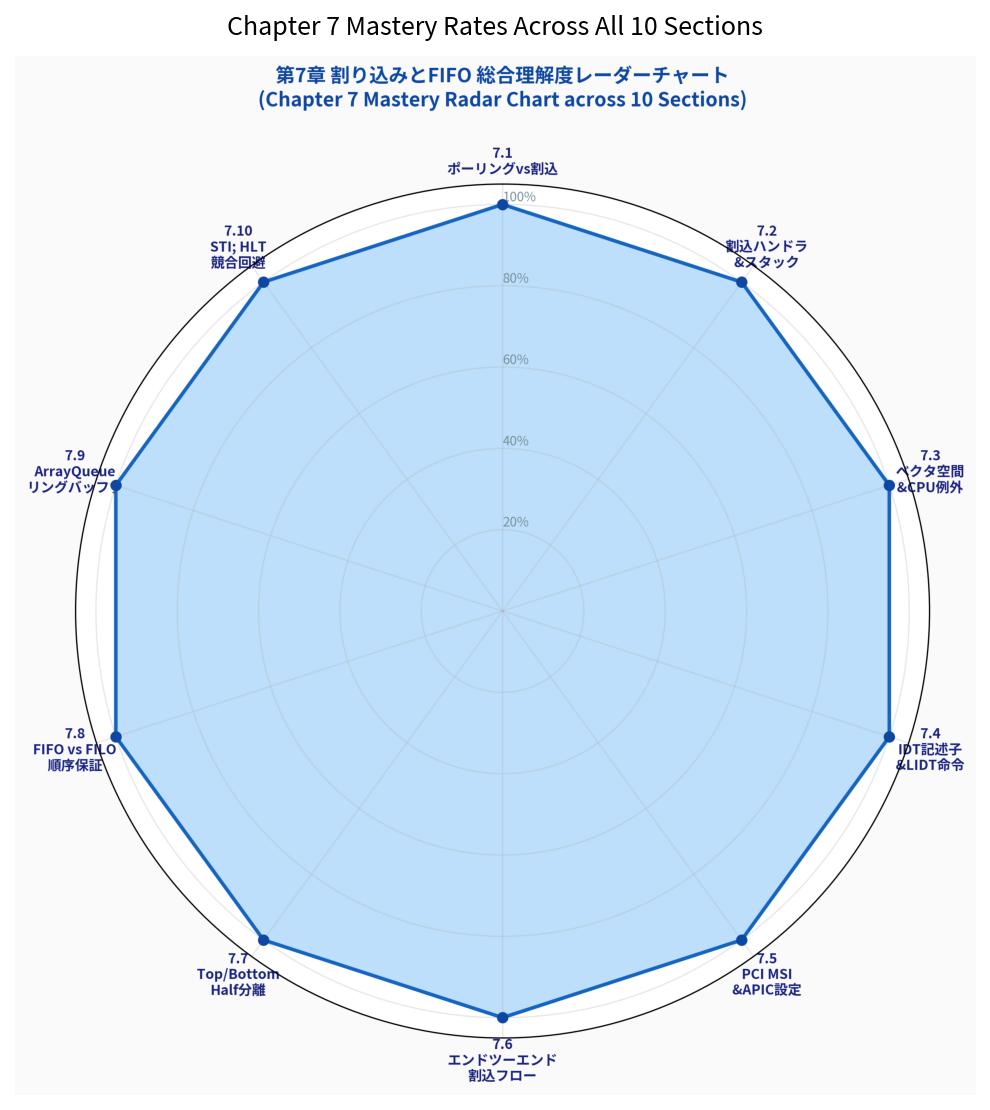

In [12]:
radar_fig_path = Path("result/fig7_ex2_ch7_mastery_radar.png")
plot_chapter7_mastery_radar(radar_fig_path, eval_result["mastery_rates"])

img_radar = Image.open(radar_fig_path)
plt.figure(figsize=(9, 9))
plt.imshow(img_radar)
plt.axis("off")
plt.title("Chapter 7 Mastery Rates Across All 10 Sections", fontsize=12, pad=10)
plt.show()


---

## 🏆 まとめと第8章への展望

本章の演習問題を通じて、以下の極めて重要な OS 低レイヤ技術を獲得しました：

1. **ハードウェア割り込みと CPU 例外**: ポーリングによる CPU 浪費の排除、0〜31 の CPU 予約例外（Fault/Trap/Abort）と 32〜255 の外部割り込みベクタ設計。
2. **16バイト IDT 記述子とアセンブリ規約**: 64ビット関数アドレスの 3分割ビットマスク（`SetIDTEntry`）、`LIDT` 命令、`__attribute__((interrupt))` によるスクラッチレジスタ退避と `IRETQ` リターン。
3. **PCI MSI（Message Signaled Interrupts）**: メモリ書き込みによる割り込み配送、Local APIC アドレス（`0xFEE00000`）とベクタ番号の設定。
4. **Top Half / Bottom Half アーキテクチャ**: 割り込みハンドラ内での重い処理（描画等）の禁止、即時キューイングとメインイベントループでの遅延処理。
5. **固定長リングバッファ `ArrayQueue<T, N>`**: ベアメタル環境における静的 FIFO キュー、循環剰余演算、満杯・空判定、マウス変位の時系列順序保証。
6. **競合状態（Race Condition）と割り込みシャドウ**: `CLI` による排他制御、チェック直後の割り込み取りこぼし（Lost Wakeup）問題、`asm("sti\n\thlt")` によるアトミック休止待機。

### 次章（第8章 メモリ管理）への展望
第7章で割り込みとイベントループが完成し、CPU を効率的に駆動できるようになりました。しかし、現在の MikanOS のメモリは UEFI が用意したメモリプールやカーネルイメージ直後の領域をアドホックに使っているに過ぎず、解放や断片化への対応ができません。
次章「第8章 メモリ管理」では、**GDT（セグメンテーション）の再設定**、**4階層ページテーブルによる 64GiB 恒等マッピング（Identity Mapping）**、そして 4KiB ページ単位の物理メモリ管理を行う **`BitmapMemoryManager`** を構築し、OS 本格運用の基盤を整えます！
